Jumlah data kosong per kolom:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

=== HASIL EVALUASI MODEL ===
RMSE : $5,796.28
R²   : 0.7836


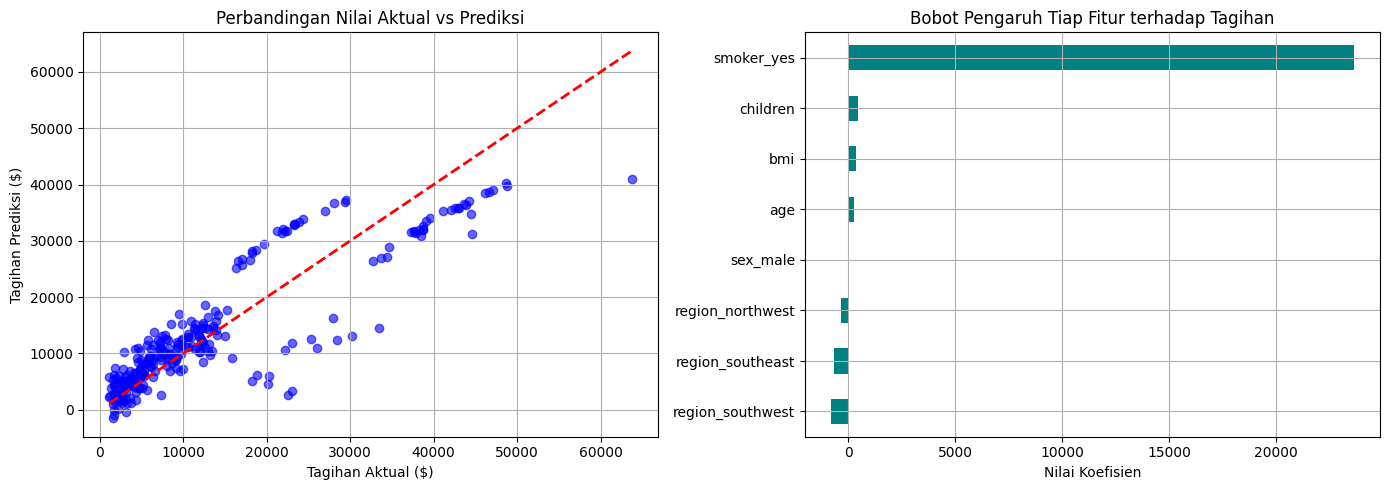

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. LOAD DATASET
url = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"
df = pd.read_csv(url)

# 2. PEMBERSIHAN & PREPROCESSING DATA
# Memeriksa data yang kosong
print("Jumlah data kosong per kolom:")
print(df.isnull().sum())

# Mengubah variabel kategorik (sex, smoker, region) menjadi angka dengan One-Hot Encoding
df_encoded = pd.get_dummies(df, columns=['sex', 'smoker', 'region'], drop_first=True)

# Memisahkan Fitur (X) dan Target (y)
X = df_encoded.drop(columns=['charges'])
y = df_encoded['charges']

# Membagi data menjadi Training Set (80%) dan Test Set (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. TRAINING MODEL
model = LinearRegression()
model.fit(X_train, y_train)

# 4. PREDIKSI & EVALUASI
y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\n=== HASIL EVALUASI MODEL ===")
print(f"RMSE : ${rmse:,.2f}")
print(f"R²   : {r2:.4f}")

# 5. VISUALISASI HASIL
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Visualisasi 1: Nilai Aktual vs Prediksi
axes[0].scatter(y_test, y_pred, alpha=0.6, color='blue')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0].set_xlabel("Tagihan Aktual ($)")
axes[0].set_ylabel("Tagihan Prediksi ($)")
axes[0].set_title("Perbandingan Nilai Aktual vs Prediksi")
axes[0].grid(True)

# Visualisasi 2: Dampak Masing-masing Fitur terhadap Tagihan
coefficients = pd.Series(model.coef_, index=X.columns).sort_values()
coefficients.plot(kind='barh', ax=axes[1], color='teal')
axes[1].set_title("Bobot Pengaruh Tiap Fitur terhadap Tagihan")
axes[1].set_xlabel("Nilai Koefisien")
axes[1].grid(True)

plt.tight_layout()
plt.show()